# Seminar 8 · Guidance and text-to-image
**Deep Generative Models · MIPT / YSDA (ШАД) · Autumn 2026**  
**12 November 2026**

From a requested MNIST digit to a text description: guidance, CLIP, GLIDE, DALL·E 2 and Imagen.

[Course repository](https://github.com/r-isachenko/2026-DGM-MIPT-YSDA-course) · [Previous MNIST practice](../seminar7/seminar7_ddpm_mnist.ipynb)

All figures and experiment outputs are embedded. The two NumPy experiments run on CPU. The [MNIST lab](seminar8_mnist_guidance.ipynb) contains the PyTorch training and sampling code. Its results are also shown in section 2.

## Route for 100 minutes

| Time | Question |
|---|---|
| 0–10 min | What does guidance add to conditional generation? |
| 10–30 min | Where does the guidance direction come from? Experiment 1. |
| 30–55 min | How can an image and a sentence be compared? CLIP and Experiment 2. |
| 55–65 min | How does GLIDE use text and guidance? |
| 65–80 min | Why does DALL·E 2 need a prior? |
| 80–95 min | What changes in Imagen? |
| 95–100 min | Compare the designs and check understanding. |

**Predict before running:** a larger guidance scale or a sharper similarity softmax need not mean better generation.

## 1. Recap: one model, two predictions

In the MNIST experiment we randomly dropped the label during training. One network learned both $\epsilon_\theta(x_t,t,y)$ and $\epsilon_\theta(x_t,t,\varnothing)$.

$$\widehat\epsilon_s=\epsilon_\theta(x_t,t,\varnothing)
+s\left[\epsilon_\theta(x_t,t,y)-\epsilon_\theta(x_t,t,\varnothing)\right].$$

- $s=0$: ignore the requested class.
- $s=1$: use the ordinary conditional prediction.
- $s>1$: extrapolate the effect of the condition.

**Question:** do we train another model for every value of $s$? **No:** we change the sampling rule.

Source: Ho & Salimans, [Classifier-Free Diffusion Guidance (2022)](https://arxiv.org/abs/2207.12598).

### Bayes gives the direction

At a fixed noise level $t$,
$$\log p_t(x_t\mid y)=\log p_t(x_t)+\log p_t(y\mid x_t)-\log p(y).$$
Since $p(y)$ does not depend on the image,
$$\underbrace{\nabla_{x_t}\log p_t(x_t\mid y)}_{g_y}
-\underbrace{\nabla_{x_t}\log p_t(x_t)}_{g_\varnothing}
=\underbrace{\nabla_{x_t}\log p_t(y\mid x_t)}_{\text{make the requested label more likely}}.$$
Thus $g_s=g_\varnothing+s(g_y-g_\varnothing)$ points along
$$\nabla_{x_t}\log\left[p_t(x_t)\,p_t(y\mid x_t)^s\right].$$

This is a **fixed-time score identity** for exact densities. For $s>1$, a reverse diffusion using these fields is not automatically an exact sampler from $p_0(x_0)p_0(y\mid x_0)^s$; the tilted marginals need not form the original forward diffusion.

**Takeaway:** stronger guidance changes the target direction; it is not a promise of uniformly better samples.

### Classifier guidance and classifier-free guidance

| | Classifier guidance | Classifier-free guidance |
|---|---|---|
| Training | Train a classifier $p_\phi(y\mid x_t,t)$ on noisy images | Train the denoiser with random condition dropout |
| Sampling | Differentiate classifier log probability with respect to $x_t$ | Combine conditional and unconditional noise predictions |
| Extra network | Noise-aware classifier | No separate classifier |

Using $g\approx-\epsilon_\theta/\sqrt{1-\bar\alpha_t}$ gives the classifier-guided prediction
$$\widehat\epsilon_s(x_t,t,y)=\epsilon_\theta(x_t,t)
-s\sqrt{1-\bar\alpha_t}\,\nabla_{x_t}\log p_\phi(y\mid x_t,t).$$
Here the base denoiser is **unconditional**. The minus sign follows from the score–noise relation.

The clean MNIST classifier from our previous evaluation is not a noise-aware guidance classifier. During guidance, gradients are taken with respect to the noisy **input**, while network weights stay fixed.

Source: Dhariwal & Nichol, [Diffusion Models Beat GANs (2021)](https://arxiv.org/abs/2105.05233).

## 2. Experiment 1: see the guidance direction

We replace images by two-dimensional points. At one fixed noise level,
$$p_t(x)=\tfrac12\mathcal N(x;\mu_0,vI)+\tfrac12\mathcal N(x;\mu_1,vI),\qquad y=1.$$

We know both component scores and the posterior class probabilities exactly. This isolates guidance from neural-network error.

**Predict:** where will guidance matter most — near the requested mode or in the ambiguous region between modes?

The plots show vector fields, not complete reverse-diffusion trajectories or generated-image quality.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
rng = np.random.default_rng(8)
COLORS = ["#2563eb", "#0d9488", "#d97706"]
print("CPU experiments · NumPy", np.__version__)

CPU experiments · NumPy 2.2.1


In [2]:
means = np.array([[-1.6, 0.0], [1.6, 0.0]])
variance = 1.2  # variance after adding noise, held fixed here

def fields(points):
    delta = points[:, None, :] - means[None, :, :]
    log_components = -np.sum(delta**2, axis=-1) / (2 * variance)
    weights = np.exp(log_components - log_components.max(axis=1, keepdims=True))
    weights /= weights.sum(axis=1, keepdims=True)
    component_scores = -delta / variance
    marginal_score = np.sum(weights[:, :, None] * component_scores, axis=1)
    conditional_score = component_scores[:, 1, :]
    classifier_gradient = conditional_score - marginal_score
    return marginal_score, conditional_score, classifier_gradient, weights[:, 1]

def log_class_probability(points):
    delta = points[:, None, :] - means[None, :, :]
    logits = -np.sum(delta**2, axis=-1) / (2 * variance)
    return logits[:, 1] - np.logaddexp(logits[:, 0], logits[:, 1])

# Independent finite-difference check of the Bayes gradient identity.
probe = rng.normal(size=(20, 2))
h = 1e-5
numerical_gradient = np.column_stack([
    (log_class_probability(probe + h * np.eye(2)[j])
     - log_class_probability(probe - h * np.eye(2)[j])) / (2 * h)
    for j in range(2)
])
error = np.max(np.abs(numerical_gradient - fields(probe)[2]))
assert error < 1e-7
print(f"Bayes gradient check: max error = {error:.2e}")

Bayes gradient check: max error = 5.87e-11


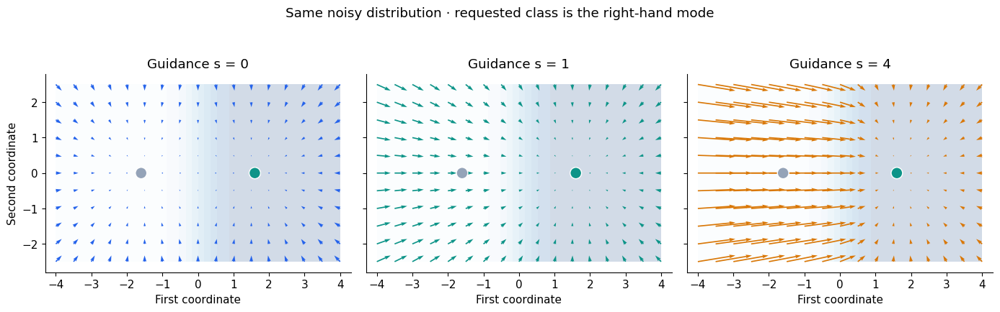

In [3]:
xx, yy = np.meshgrid(np.linspace(-4, 4, 17), np.linspace(-2.5, 2.5, 11))
points = np.column_stack([xx.ravel(), yy.ravel()])
g0, gy, correction, posterior = fields(points)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
for ax, scale, color in zip(axes, [0, 1, 4], COLORS):
    guided = g0 + scale * correction
    ax.contourf(xx, yy, posterior.reshape(xx.shape), levels=np.linspace(0, 1, 11),
                cmap="Blues", alpha=0.18)
    # Same arrow scaling in every panel; magnitudes remain comparable.
    ax.quiver(points[:, 0], points[:, 1], guided[:, 0], guided[:, 1],
              color=color, angles="xy", scale_units="xy", scale=12, width=0.004)
    ax.scatter(*means.T, s=130, c=["#94a3b8", "#0d9488"], edgecolors="white", zorder=5)
    ax.set(title=f"Guidance s = {scale}", xlabel="First coordinate", xlim=(-4.3, 4.3), ylim=(-2.8, 2.8))
    ax.set_aspect("equal")
axes[0].set_ylabel("Second coordinate")
fig.suptitle("Same noisy distribution · requested class is the right-hand mode", y=1.01)
fig.tight_layout()
plt.show()

### Read the result

At $s=0$, each region is attracted toward the mixture density. At $s=1$, the field is exactly the score of the right Gaussian. At $s=4$, the classifier correction is amplified, especially where the requested class is unlikely.

**Try:** increase `variance` from 1.2 to 3.0 and rerun the two cells. More overlap changes the region in which the label is ambiguous. Restore 1.2 for the saved baseline.

### MNIST · Classifier guidance vs CFG

[Run the MNIST lab](seminar8_mnist_guidance.ipynb). Both methods start from the same null-label denoiser. CG adds the gradient of a classifier trained at every noise level. CFG uses the conditional prediction of the same U-Net. Each column below holds the initial noise fixed while the requested digit is 7. The shared baseline uses $s=0$.

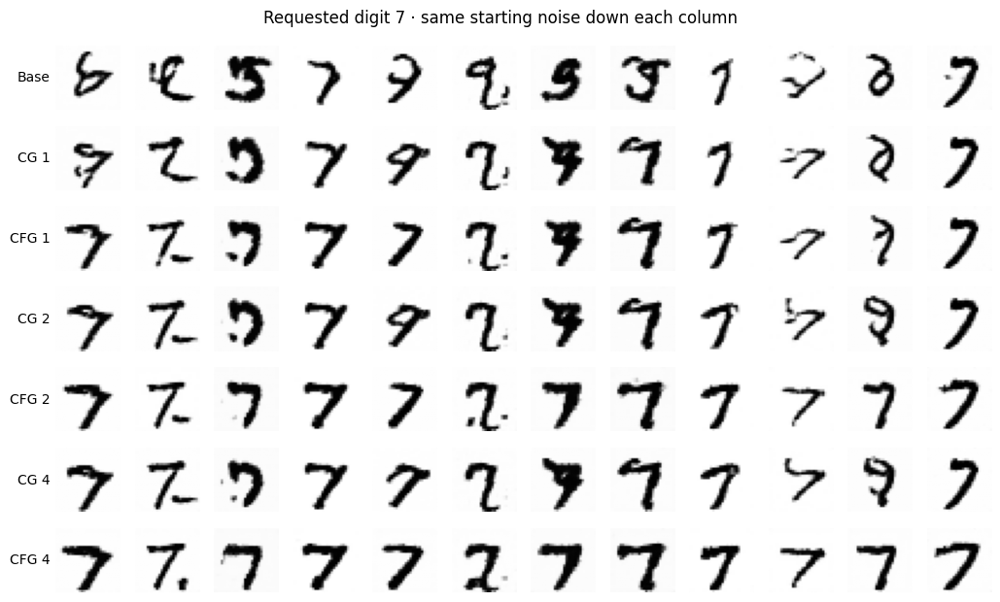

**Watch how the seven emerges.** The top row uses classifier guidance, the bottom row uses CFG. Both use $s=2$, the same starting noise per column, and 50 DDIM steps.

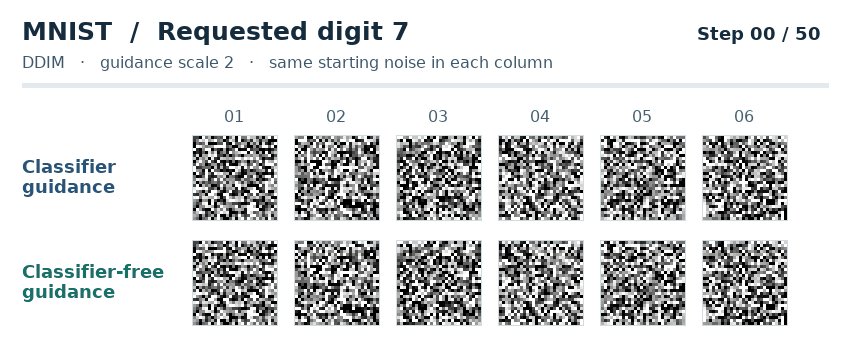

| Method | Scale | Requested digit recognized | Within-class distance | Digits with ≥2 matches |
|---|---:|---:|---:|---:|
| Shared base | 0 | 30 / 240 (12.5%) | 0.620 | 9 / 10 |
| CG | 1 | 134 / 240 (55.8%) | 0.601 | 10 / 10 |
| CFG | 1 | 207 / 240 (86.2%) | 0.518 | 10 / 10 |
| CG | 2 | 175 / 240 (72.9%) | 0.572 | 10 / 10 |
| CFG | 2 | 238 / 240 (99.2%) | 0.399 | 10 / 10 |
| CG | 4 | 202 / 240 (84.2%) | 0.536 | 10 / 10 |
| CFG | 4 | 240 / 240 (100.0%) | 0.327 | 10 / 10 |

At $s=2$ the independent evaluator recognizes 72.9% of CG samples and 99.2% of CFG samples as the requested digit. Among recognized matches, the mean within-digit distances are 0.572 and 0.399, respectively. These estimates use 24 starts per digit and one training run.

**Transition:** how can we replace a fixed set of digit labels with a text prompt?

## 3. How CLIP learned from image–text pairs

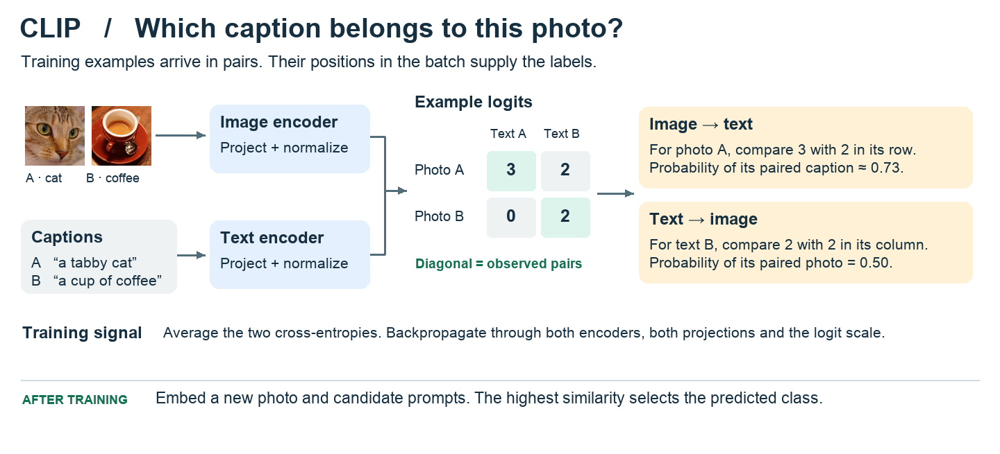

The original CLIP was trained from scratch on 400 million image–text pairs collected from the web. The supervision comes from the pairing itself. A photo with the caption “a dog catching a frisbee” supplies one positive example.

**Build one minibatch.** Draw $B$ pairs $(x_i,c_i)$. Run each image through a ResNet or Vision Transformer and each tokenized caption through a text Transformer. Each encoder has its own learned linear projection into a shared space. Normalize the projected vectors to unit length.

$$
u_i=\frac{W_I f_I(x_i)}{\lVert W_I f_I(x_i)\rVert_2},
\qquad
v_j=\frac{W_T f_T(c_j)}{\lVert W_T f_T(c_j)\rVert_2}.
$$

**Compare all pairs.** Each encoder processes $B$ inputs. One matrix multiplication gives $B^2$ logits, one for every combination of an image and a caption.

$$
L_{ij}=e^a\,u_i^\top v_j=\frac{u_i^\top v_j}{\tau},
\qquad \tau=e^{-a}.
$$

The dot product is cosine similarity because both vectors have unit length. The learned scalar $a$ controls how strongly differences in similarity affect the softmax. Row $i$ contains all candidate captions for image $i$. Column $j$ contains all candidate images for caption $j$. With pairs stored in matching order, the $B$ observed matches lie on the diagonal.

In the original run, a minibatch contained 32,768 pairs. Each image therefore competed against 32,767 other captions. The temperature started at $0.07$ and was learned during training. [Training details, §2.4](https://arxiv.org/html/2103.00020v1)

[Radford et al., CLIP, §§2.1–2.3 and Figure 3 (2021)](https://proceedings.mlr.press/v139/radford21a/radford21a.pdf)

Example photographs from [scikit-image sample data](https://scikit-image.org/docs/stable/api/skimage.data.html).

### CLIP training and zero-shot classification

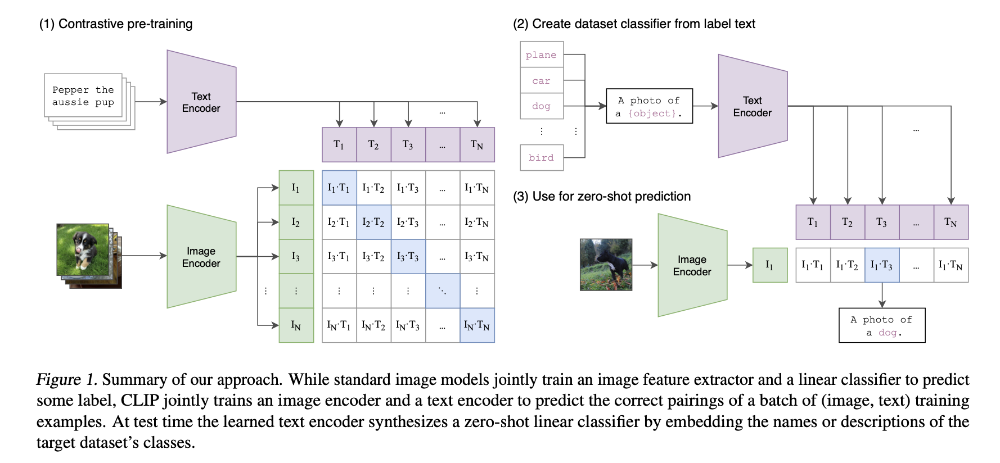

On the left, follow one training pair to its diagonal entry. On the right, the trained text encoder embeds candidate class prompts such as “a photo of a dog”. Zero-shot classification picks the prompt whose embedding has the highest cosine similarity to the image embedding.

Source: [Radford et al., CLIP, Figure 1 (2021)](https://arxiv.org/abs/2103.00020).

### One matrix, two retrieval tasks

Suppose a batch contains a **cat** photo with its caption and a **cup of coffee** photo with its caption. Consider these illustrative logits after temperature scaling.

| Image | “a tabby cat” | “a cup of coffee” |
|---|---:|---:|
| Cat photo | **3** | 2 |
| Coffee photo | 0 | **2** |

**Image → text.** Read the first row. The cat photo gives its own caption probability $e^3/(e^3+e^2)\approx0.731$. Its contribution to cross-entropy is $-\log(0.731)\approx0.313$. For the coffee photo the correct-caption probability is $0.881$. The mean loss over the two rows is $0.220$.

**Text → image.** Read the second column. The coffee caption gives both photos a logit of 2, so its correct-image probability is $0.5$ and its loss is $0.693$. The cat caption picks its photo with probability $0.953$. The mean loss over the two columns is $0.371$. The row and column questions use different sets of competitors, even for the same diagonal entry.

For a batch of size $B$, the two cross-entropies and the training objective are

$$
\begin{aligned}
\mathcal L_{I\to T}
 &= -\frac1B\sum_{i=1}^B \log
 \frac{e^{L_{ii}}}{\sum_{j=1}^B e^{L_{ij}}},\\[3pt]
\mathcal L_{T\to I}
 &= -\frac1B\sum_{j=1}^B \log
 \frac{e^{L_{jj}}}{\sum_{i=1}^B e^{L_{ij}}},\\[3pt]
\mathcal L_{\mathrm{CLIP}}
 &= \tfrac12\bigl(\mathcal L_{I\to T}+\mathcal L_{T\to I}\bigr).
\end{aligned}
$$

In the example the symmetric loss is about $0.295$. If all logits in a batch are equal, every correct match gets probability $1/B$ and the loss is $\log B$.

**What one update does.** For a single row with softmax probabilities $p_{ij}$, the derivative of its cross-entropy with respect to logit $L_{ij}$ is $p_{ij}-\mathbf{1}_{i=j}$. For the cat photo the two derivatives are about $-0.269$ and $+0.269$. Gradient descent therefore favors a higher score for its own caption and a lower score for the competing caption. The column loss supplies a second gradient. Backpropagation carries their average through the matrix product and normalization into **both encoders, both projection matrices and the logit scale**. The next batch supplies new competitors.

**Question for the room.** Suppose two different photos both show a dog catching a frisbee. Each paired caption is a positive for its own image. The other caption is an in-batch negative under this objective, even if it also describes the image well.

[Radford et al., CLIP, §2.2 (2021)](https://proceedings.mlr.press/v139/radford21a/radford21a.pdf)

## 4. Experiment 2: temperature is not better understanding

We construct four **synthetic** image/text embedding pairs. These are not outputs of a pretrained CLIP model. The experiment isolates the similarity matrix, symmetric loss and softmax temperature.

**Predict:** if we divide the same similarities by a smaller positive temperature, can the top-ranked caption change?

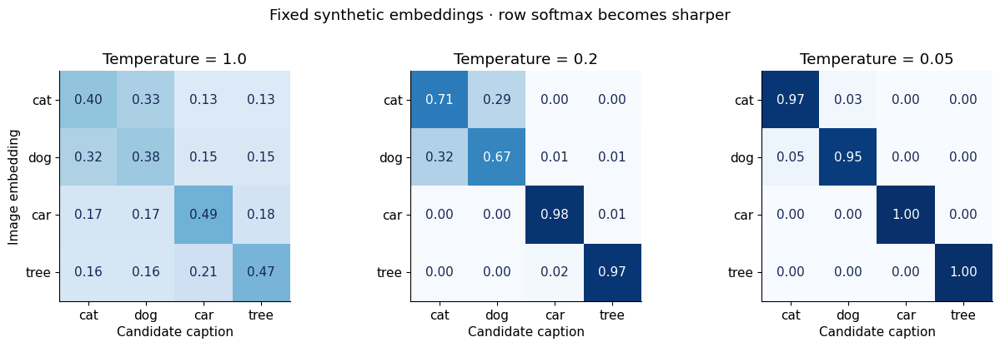

temperature=1.00: symmetric loss=0.8431
temperature=0.20: symmetric loss=0.1978
temperature=0.05: symmetric loss=0.0193
Top-1 labels do not change under positive rescaling.


In [4]:
labels = ["cat", "dog", "car", "tree"]
# Construct nearby image/text vectors; cat and dog are intentionally similar.
text_vectors = np.array([[1., 0., 0., 0.], [0.85, 0.53, 0., 0.],
                         [0., 0., 1., 0.], [0., 0., 0., 1.]])
text_vectors /= np.linalg.norm(text_vectors, axis=1, keepdims=True)
image_vectors = text_vectors + rng.normal(0, 0.08, text_vectors.shape)
image_vectors /= np.linalg.norm(image_vectors, axis=1, keepdims=True)
similarity = image_vectors @ text_vectors.T

def softmax(logits):
    exp_logits = np.exp(logits - logits.max(axis=-1, keepdims=True))
    return exp_logits / exp_logits.sum(axis=-1, keepdims=True)

def symmetric_loss(logits):
    def ce(a):
        a = a - a.max(axis=1, keepdims=True)
        return np.mean(np.log(np.exp(a).sum(axis=1)) - np.diag(a))
    return 0.5 * (ce(logits) + ce(logits.T))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, temperature in zip(axes, [1.0, 0.2, 0.05]):
    probabilities = softmax(similarity / temperature)
    ax.imshow(probabilities, vmin=0, vmax=1, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{probabilities[i,j]:.2f}", ha="center", va="center",
                    color="white" if probabilities[i,j] > 0.55 else "#172554")
    ax.set(xticks=range(4), xticklabels=labels, yticks=range(4), yticklabels=labels,
           xlabel="Candidate caption", title=f"Temperature = {temperature}")
axes[0].set_ylabel("Image embedding")
fig.suptitle("Fixed synthetic embeddings · row softmax becomes sharper", y=1.02)
fig.tight_layout()
plt.show()
for temperature in [1.0, 0.2, 0.05]:
    assert np.array_equal((similarity / temperature).argmax(1), similarity.argmax(1))
    print(f"temperature={temperature:4.2f}: symmetric loss={symmetric_loss(similarity/temperature):.4f}")
print("Top-1 labels do not change under positive rescaling.")

In [5]:
# Break the supplied pairing without changing the vectors themselves.
wrong_order = [2, 1, 0, 3]
correct_loss = symmetric_loss(similarity / 0.2)
wrong_loss = symmetric_loss(similarity[:, wrong_order] / 0.2)
print(f"Correct pairing loss: {correct_loss:.3f}")
print(f"Wrong pairing loss:   {wrong_loss:.3f}")
assert wrong_loss > correct_loss

Correct pairing loss: 0.198
Wrong pairing loss:   2.916


### What this experiment establishes

Temperature changes probabilities and loss even when the ranking stays fixed. These candidate-set probabilities are not automatically calibrated semantic confidence.

**Try:** make a wrong caption the most similar vector, then lower the temperature. The model becomes more confident in the wrong answer. Increasing confidence is not equivalent to learning a better representation.

**Transition:** a compatibility function can guide generation, but it still needs a generative model to turn noise into pixels.

## 5. GLIDE: text-conditioned diffusion

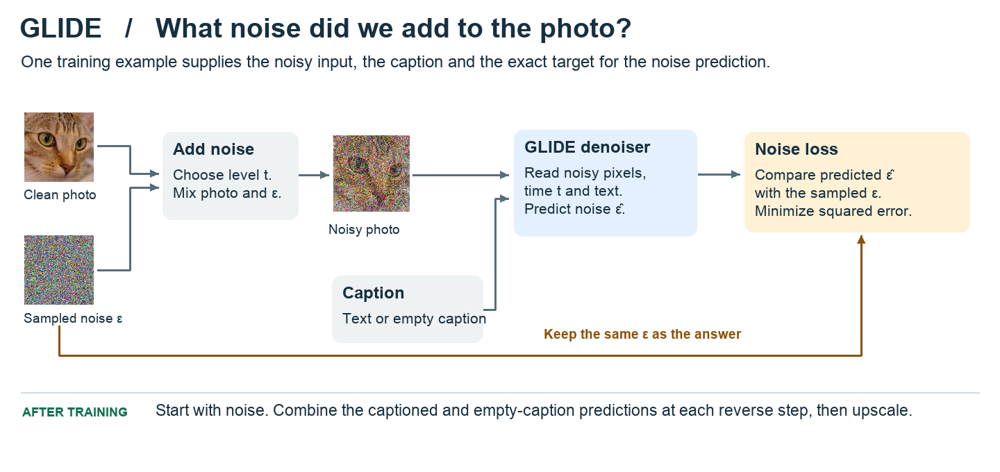

**Training**
1. Encode caption tokens with a text Transformer.
2. Condition the denoiser on text features and the noise level.
3. Drop the caption on some examples to enable CFG.

**Sampling**
1. Initialize the image with Gaussian noise.
2. Combine conditional and unconditional predictions at each step.
3. Denoise to obtain an image, then use the super-resolution stage.

GLIDE compares CFG with guidance based on CLIP image–text similarity. Its CLIP guidance uses a **noise-aware image encoder**, not simply the unchanged clean-image CLIP encoder.

Source: Nichol et al., [GLIDE (2021)](https://arxiv.org/abs/2112.10741).

Example photographs from [scikit-image sample data](https://scikit-image.org/docs/stable/api/skimage.data.html).

### GLIDE: read the quality–diversity trade-off

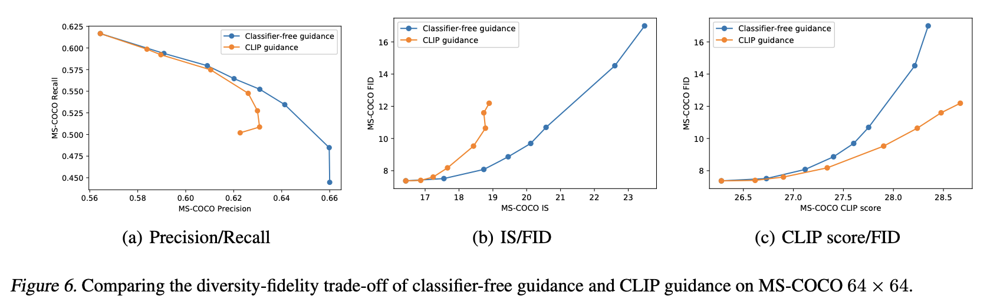

Each curve sweeps guidance strength. Read precision and recall together; do not choose a model from a single best-looking sample.

Source: [Nichol et al., GLIDE, Figure 6](https://arxiv.org/abs/2112.10741).

### GLIDE: human evaluation

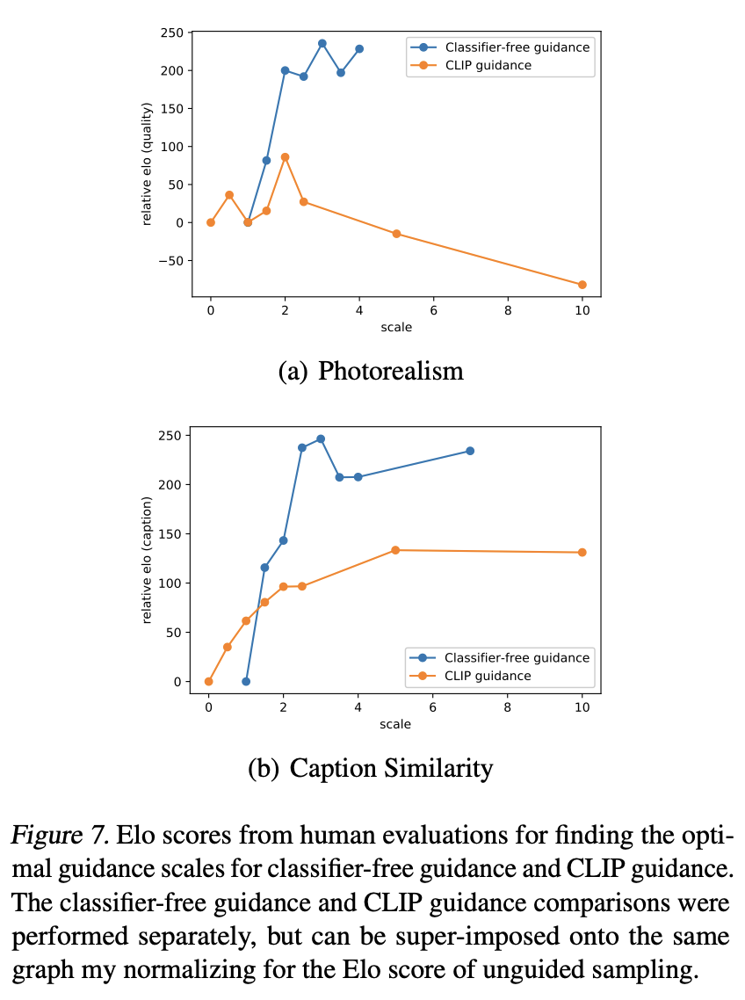

In this comparison, raters favored CFG over CLIP guidance for photorealism and caption similarity. This does not establish that every CFG implementation beats every CLIP-guided system.

Source: [Nichol et al., GLIDE, Figure 7](https://arxiv.org/abs/2112.10741).

## 6. DALL·E 2: generate a representation first

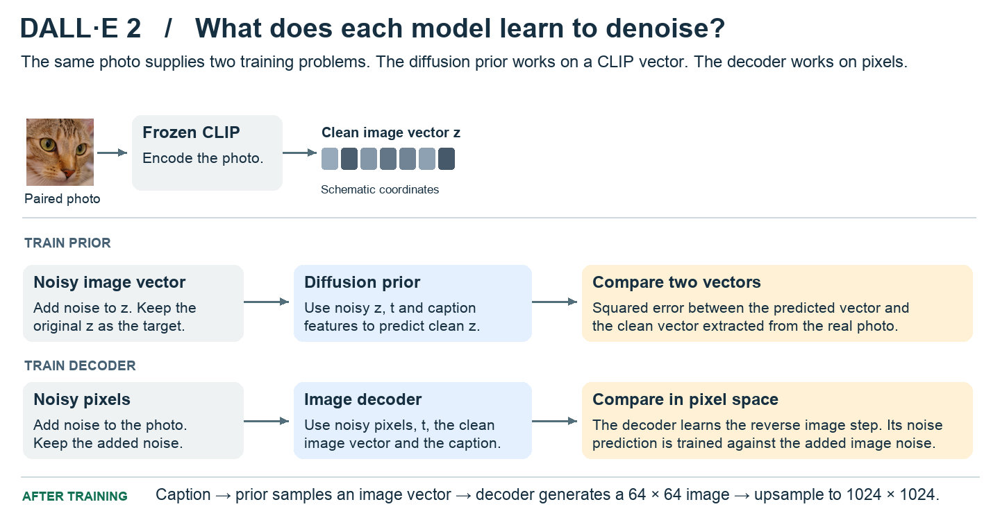

**Question:** CLIP has a text embedding and an image embedding. If a decoder was trained on image embeddings, should we assume a text embedding is a drop-in replacement?

**No.** Alignment supports comparison; it does not make their conditional distributions identical. A prior learns to predict a distribution of image embeddings from the caption.

Use $c$ for the caption and $z_I$ for a CLIP image embedding, so $z_I$ is not confused with a noisy diffusion state $x_t$.

Example photographs from [scikit-image sample data](https://scikit-image.org/docs/stable/api/skimage.data.html).

### DALL·E 2 architecture

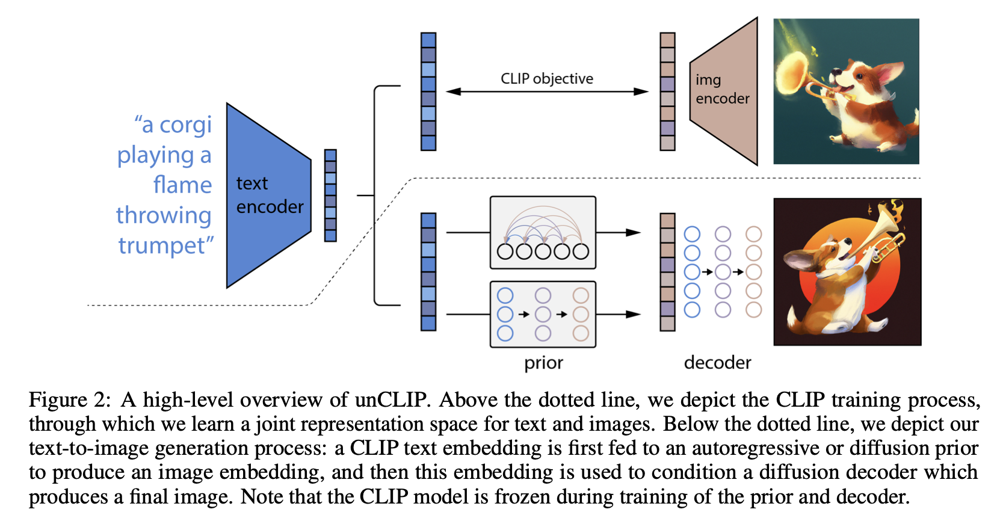

Follow the generation path below the dotted line. The prior creates an image embedding; the decoder produces pixels.

Source: [Ramesh et al., Hierarchical Text-Conditional Image Generation with CLIP Latents, Figure 2 (2022)](https://arxiv.org/abs/2204.06125).

### Two conditional generative problems

$$p(x\mid c)=\int p_\theta(x\mid z_I,c)\,p_\psi(z_I\mid c)\,dz_I.$$

**Training**
1. Extract CLIP image embeddings for training images.
2. Train the prior to model image embeddings conditioned on captions.
3. Train the decoder on image embeddings and captions.

**Sampling**
1. Sample $z_I$ from the prior given the caption.
2. Generate a $64\times64$ image with the diffusion decoder.
3. Upsample to $256\times256$ and then $1024\times1024$.

For image variations, use the source image embedding instead of sampling it from the text prior. The embedding does not preserve every pixel detail.

Source: [Ramesh et al., DALL·E 2 (2022)](https://arxiv.org/abs/2204.06125).

### Why a prior matters

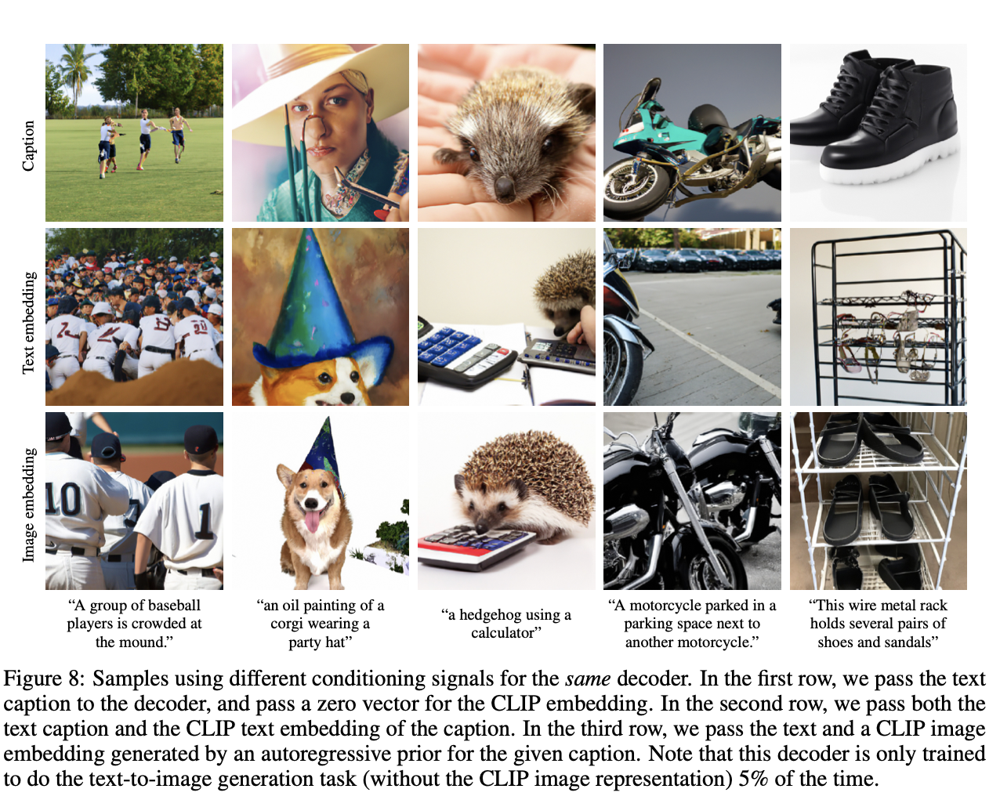

Compare the conditioning strategies within each prompt. Matching embedding dimensions is not enough to make two representations interchangeable.

Source: [Ramesh et al., DALL·E 2, Figure 8](https://arxiv.org/abs/2204.06125).

### Discussion: where can variation enter?

For the same caption, we can vary the prior's sampled embedding and the decoder's sampling noise. To isolate their roles, hold one fixed and vary the other.

This suggests a controlled experiment rather than a claim that the two sources of randomness always affect disjoint visual properties.

**Transition:** must text representation learning always use image–caption pairs?

## 7. Imagen: a frozen language encoder as the condition

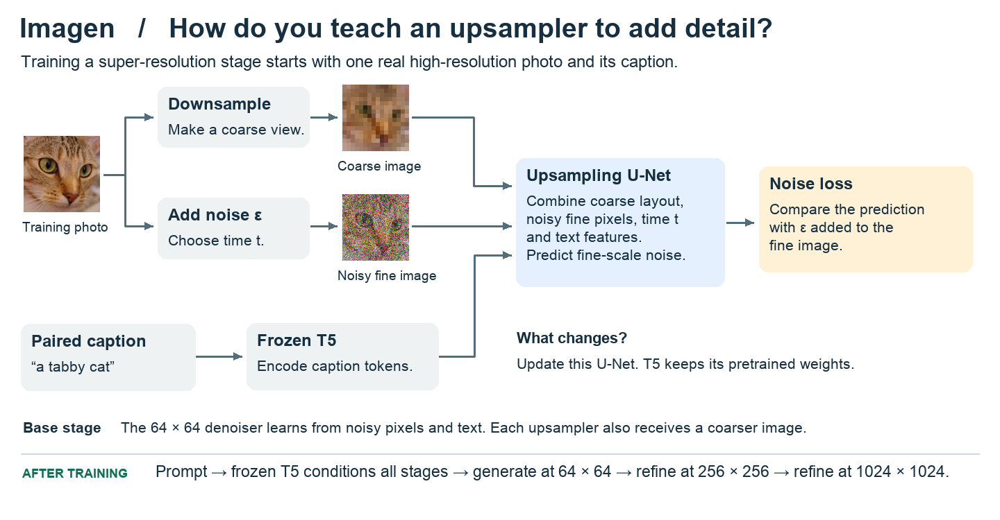

Imagen uses a pretrained, frozen T5 text encoder and a diffusion cascade: $64\times64\to256\times256\to1024\times1024$.

The encoder supplies language features; the image models still learn from image–text pairs. Text-only pretraining of the encoder does **not** imply text-only training of the generator.

In the paper's ablations, scaling the text encoder improved results more than scaling the image denoiser. Treat this as a result for the tested configurations.

Source: Saharia et al., [Imagen (2022)](https://arxiv.org/abs/2205.11487).

Example photographs from [scikit-image sample data](https://scikit-image.org/docs/stable/api/skimage.data.html).

### Imagen architecture

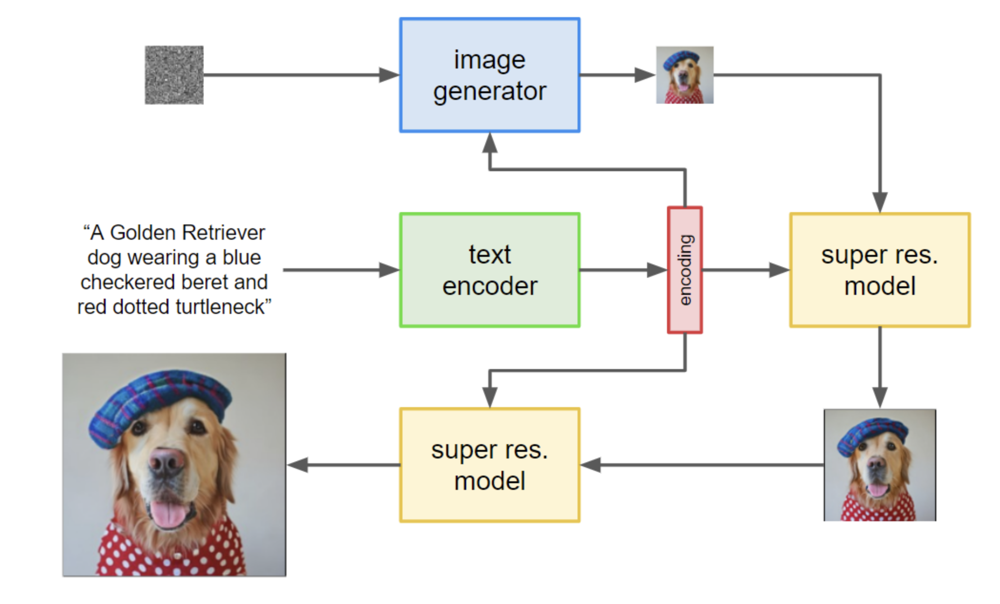

The text condition guides the base generator and the super-resolution stages. The frozen language encoder is not itself the image generator.

Source: [Saharia et al., Imagen, Figure 2](https://arxiv.org/abs/2205.11487).

### Strong guidance and pixel range

When pixels are normalized to $[-1,1]$, extrapolated noise predictions can produce out-of-range clean-image estimates:
$$\widehat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\,\widehat\epsilon_s}{\sqrt{\bar\alpha_t}}.$$

Static thresholding clips this estimate to $[-1,1]$. Dynamic thresholding uses a per-image percentile:
$$r=\max\{1,\operatorname{quantile}_p(|\widehat x_0|)\},\qquad
\widehat x_0\leftarrow\frac{\operatorname{clip}(\widehat x_0,-r,r)}{r}.$$

Here $r$ is a **threshold**, not the guidance scale $s$. Apply the operation to the predicted clean image during sampling, not to the displayed final image only.

This pixel-space rule should not be transferred blindly to arbitrary latent coordinates.

Source: [Saharia et al., Imagen, §2.3](https://arxiv.org/abs/2205.11487).

### Thresholding at stronger guidance

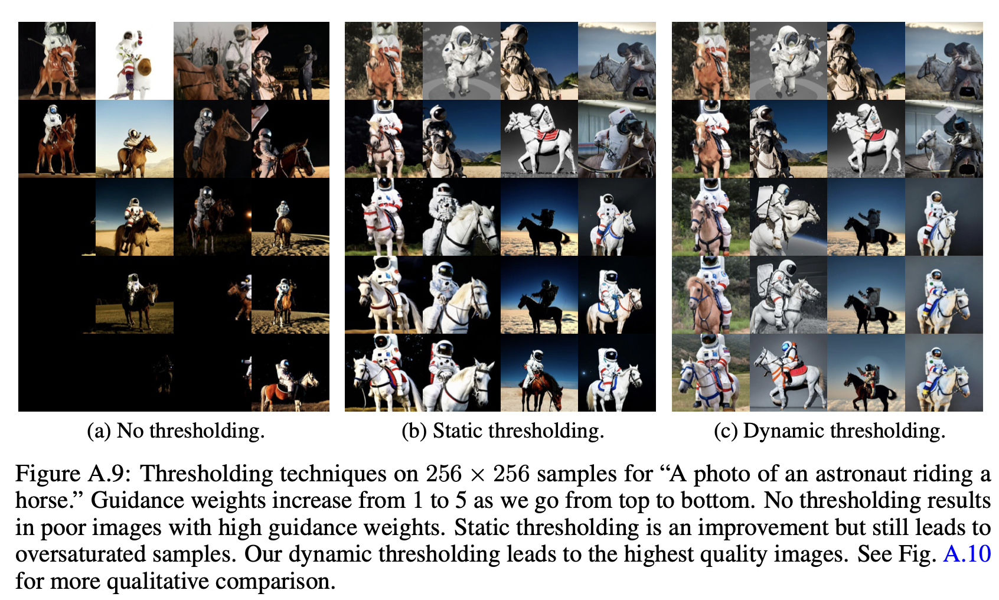

Compare the same guidance row across the three methods; compare guidance strengths within a column. Separate the intervention from the guidance scale.

Source: [Saharia et al., Imagen, Figure A.9](https://arxiv.org/abs/2205.11487).

## 8. Compare the designs

| System | Representation / role | What generates pixels? |
|---|---|---|
| CLIP | Image–text compatibility | No pixel generator |
| GLIDE | Text Transformer conditions diffusion | Diffusion model and upsampler |
| DALL·E 2 | Text-conditioned prior produces CLIP image embedding | Diffusion decoder and upsamplers |
| Imagen | Frozen language encoder supplies text features | Base diffusion model and super-resolution cascade |

**Takeaways**
- Guidance changes the sampling direction; conditioning must be learned.
- A compatibility model and a generative model solve different problems.
- Aligned representations need not be interchangeable as decoder inputs.
- Stronger guidance requires checking both fidelity and diversity.
- Control the seed, model and compute budget when comparing settings.

**Next:** latent diffusion — move the expensive diffusion process into a learned image latent space.

### Check your understanding

1. Why does classifier guidance need a classifier trained on noisy inputs?
2. Does reducing CLIP temperature change the top-ranked caption for fixed embeddings?
3. What does the DALL·E 2 prior generate?
4. Does a frozen T5 encoder mean Imagen is trained without images?
5. What should be fixed when comparing guidance scales?

**Answers:** 1. Sampling visits noisy states at different $t$. 2. No, for positive temperature. 3. A CLIP image embedding conditioned on text. 4. No; image generators learn from image–text pairs. 5. Model weights, initial noise / seeds, sampler, steps and evaluation set; measure diversity as well as condition agreement.